# 🔬 Semi-Supervised Learning for Magnetism (JARVIS-DFT)
## Demonstrating SSL with limited labeled data

---

### 🎯 Objective
Train with only **1,000 labeled compositions** and compare a supervised baseline with five semi-supervised methods (Label Propagation, Label Spreading, Self-Training, Co-Training, Cluster-then-Label) and self-supervised pre-training, while the unlabeled pool grows from 1,000 to 100,000 compositions.

The full sweep (3 seeds × 4 pool sizes × 2 unlabeled-pool settings, Optuna tuning) is run by `pipeline/run_ssl_experiments.py`; this notebook loads its results and re-runs every method once live.

In [1]:
import sys, warnings, json
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parents[1]
sys.path.insert(0, str(ROOT / "pipeline"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
sns.set_theme(style="whitegrid")
TASK = "magnetism"
PRED = ROOT / "data" / "predictions" / TASK
from IPython.display import Image, display

In [2]:
print("=" * 100); print("STEP 1: LOADING EXPERIMENT RESULTS"); print("=" * 100)
summ = {p: json.loads((PRED / p / f'ssl_summary_{TASK}.json').read_text()) for p in ('indist', 'gnome') if (PRED / p / f'ssl_summary_{TASK}.json').exists()}
res = {p: pd.read_csv(PRED / p / f'ssl_results_{TASK}.csv') for p in summ}
for p, s in summ.items():
    print(p, json.dumps(s['training_setup'], indent=1))

STEP 1: LOADING EXPERIMENT RESULTS
indist {
 "n_labeled_compositions_total": 64410,
 "n_train_pool": 51528,
 "n_test": 12882,
 "n_test_evaluated": 12882,
 "labeled_budget": 1000,
 "unlabeled_pool": "same database, labels hidden",
 "unlabeled_pool_size": 50528,
 "unlabeled_sizes_tested": [
  1000,
  5000,
  25000,
  50528
 ],
 "seeds": 3,
 "n_features": 142,
 "co_training_views": [
  132,
  10
 ],
 "stratified_sampling": true,
 "metric_used_for_selection": "Composite Score (mean of F1 & ROC-AUC), averaged over seeds"
}
gnome {
 "n_labeled_compositions_total": 64410,
 "n_train_pool": 51528,
 "n_test": 12882,
 "n_test_evaluated": 12882,
 "labeled_budget": 1000,
 "unlabeled_pool": "GNoME",
 "unlabeled_pool_size": 553883,
 "unlabeled_sizes_tested": [
  1000,
  5000,
  25000,
  100000
 ],
 "seeds": 3,
 "n_features": 142,
 "co_training_views": [
  132,
  10
 ],
 "stratified_sampling": true,
 "metric_used_for_selection": "Composite Score (mean of F1 & ROC-AUC), averaged over seeds"
}


In [3]:
print("STEP 2-3: BASELINE MODEL ZOO (supervised, 1,000 labels, mean over 3 seeds)")
r = res['indist']
zoo = r[r.Method == 'Baseline'].groupby('Config')[['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC', 'Composite_Score']].agg(['mean', 'std'])
zoo.sort_values(('Composite_Score', 'mean'), ascending=False).round(4)

STEP 2-3: BASELINE MODEL ZOO (supervised, 1,000 labels, mean over 3 seeds)


Accuracy         Precision          Recall         F1-Score         ROC-AUC         Composite_Score        
                         mean     std      mean     std    mean     std     mean     std    mean     std            mean     std
Config                                                                                                                          
LightGBM (tuned)       0.8674  0.0022    0.6791  0.0078  0.6752  0.0249   0.6769  0.0106  0.9085  0.0019          0.7927  0.0062
LightGBM (default)     0.8727  0.0026    0.7202  0.0053  0.6243  0.0291   0.6685  0.0147  0.9099  0.0024          0.7892  0.0083
XGBoost (default)      0.8732  0.0028    0.7472  0.0044  0.5802  0.0265   0.6529  0.0152  0.9117  0.0022          0.7823  0.0087
XGBoost (tuned)        0.8697  0.0042    0.7319  0.0050  0.5785  0.0257   0.6461  0.0175  0.9072  0.0015          0.7766  0.0093
ExtraTrees (default)   0.8650  0.0048    0.7508  0.0031  0.5153  0.0387   0.6105  0.0268  0.9023  0.0064          0.7564  0.0165
RF (default)           0.8651  0.0031    0.7730  0.0070  0.4882  0.0265   0.5981  0.0183  0.9085  0.0037          0.7533  0.0110
LogReg (default)       0.7890  0.0121    0.4926  0.0187  0.7566  0.0289   0.5962  0.0114  0.8540  0.0073          0.7251  0.0092
MLP (default)          0.8336  0.0047    0.6512  0.0188  0.4129  0.0254   0.5050  0.0206  0.8369  0.0019          0.6710  0.0112
kNN (default)          0.8282  0.0091    0.6287  0.0333  0.4029  0.0401   0.4906  0.0369  0.8265  0.0205          0.6586  0.0287

In [4]:
print("STEP 4: OPTUNA HYPER-PARAMETER SEARCH (25 trials, 5-fold CV)")
pd.DataFrame({'CV composite': summ['indist']['optuna_cv_scores'], 'best params': {k: str(v) for k, v in summ['indist']['tuned_params'].items()}})

STEP 4: OPTUNA HYPER-PARAMETER SEARCH (25 trials, 5-fold CV)


,CV composite,best params
LightGBM,0.770691,"{'n_estimators': 800, 'num_leaves': 58, 'learn..."
XGBoost,0.760267,"{'n_estimators': 400, 'max_depth': 5, 'learnin..."


In [5]:
print("STEP 4b: SELF-SUPERVISED PRE-TRAINING (masked autoencoder on 554k GNoME)")
r[r.Method == 'Self-Supervised (AE)'].groupby('Config')[['F1-Score', 'ROC-AUC', 'Composite_Score']].agg(['mean', 'std']).round(4)

STEP 4b: SELF-SUPERVISED PRE-TRAINING (masked autoencoder on 554k GNoME)


F1-Score        ROC-AUC         Composite_Score        
                                 mean    std    mean     std            mean     std
Config                                                                              
LightGBM* on ae features       0.5986  0.016  0.8612  0.0030          0.7299  0.0093
LightGBM* on raw+ae features   0.6715  0.006  0.9066  0.0016          0.7891  0.0024

In [6]:
print("STEP 5-8: SEMI-SUPERVISED SWEEP – mean composite per pool size")
for p, r_ in res.items():
    print(f'--- unlabeled pool: {p}')
    ssl = r_[~r_.Method.isin(['Baseline', 'Self-Supervised (AE)'])]
    display(ssl.pivot_table(index=['Method', 'Config'], columns='N_Unlabeled', values='Composite_Score', aggfunc='mean').round(4))

STEP 5-8: SEMI-SUPERVISED SWEEP – mean composite per pool size
--- unlabeled pool: indist


N_Unlabeled                                                  1000    5000    25000   50528
Method             Config                                                                 
Cluster-then-Label CtL LightGBM* k=100 purity=0.8           0.7804  0.7491  0.6968  0.6980
                   CtL LightGBM* k=100 purity=0.8 [raw+AE]  0.7737  0.7398  0.6990  0.6871
Co-Training        CT LightGBM* tau=0.85                    0.7181  0.6579  0.6429  0.6407
                   CT RF tau=0.85                           0.6632  0.6480     NaN     NaN
Label Propagation  LP knn k=10                              0.6738  0.6593  0.6433  0.6231
                   LP rbf                                   0.6109  0.6054     NaN     NaN
Label Spreading    LS knn k=10 alpha=0.2                    0.6772  0.6692  0.6479  0.6336
                   LS knn k=10 alpha=0.2 [AE space]         0.6600  0.6482  0.6249  0.6065
                   LS knn k=10 alpha=0.8                    0.6590  0.6692  0.6579  0.6424
                   LS rbf alpha=0.2                         0.6091  0.5951     NaN     NaN
Self-Training      ST LightGBM* tau=0.75                    0.7948  0.7913     NaN     NaN
                   ST LightGBM* tau=0.9                     0.7950  0.7914  0.7933  0.7940
                   ST LightGBM* tau=0.9 [raw+AE]            0.7893  0.7823     NaN     NaN
                   ST RF tau=0.75                           0.7303  0.6905     NaN     NaN

--- unlabeled pool: gnome


N_Unlabeled                                                 1000    5000    25000   100000
Method             Config                                                                 
Cluster-then-Label CtL LightGBM* k=100 purity=0.8           0.7818  0.7647  0.7263  0.7195
                   CtL LightGBM* k=100 purity=0.8 [raw+AE]  0.7808  0.7526  0.7226  0.6983
Co-Training        CT LightGBM* tau=0.85                    0.7334  0.7003  0.6846  0.6727
                   CT RF tau=0.85                           0.6650  0.6533     NaN     NaN
Label Propagation  LP knn k=10                              0.6630  0.6481  0.6287  0.6166
                   LP rbf                                   0.6070  0.6015     NaN     NaN
Label Spreading    LS knn k=10 alpha=0.2                    0.6673  0.6578  0.6430  0.6217
                   LS knn k=10 alpha=0.2 [AE space]         0.6495  0.6437  0.6295  0.6099
                   LS knn k=10 alpha=0.8                    0.6518  0.6518  0.6453  0.6415
                   LS rbf alpha=0.2                         0.6050  0.5907     NaN     NaN
Self-Training      ST LightGBM* tau=0.75                    0.7828  0.7774     NaN     NaN
                   ST LightGBM* tau=0.9                     0.7789  0.7670  0.7707  0.7751
                   ST LightGBM* tau=0.9 [raw+AE]            0.7729  0.7623     NaN     NaN
                   ST RF tau=0.75                           0.6947  0.6494     NaN     NaN

In [7]:
print("STEP 9: COMPREHENSIVE RESULTS COMPARISON (best configuration per method)")
for p, s in summ.items():
    print(f'--- unlabeled pool: {p}')
    b = pd.DataFrame(s['best_per_method'])[['Method', 'Model_Config', 'Composite_Score_mean', 'Composite_Score_std', 'F1-Score_mean', 'ROC-AUC_mean', 'Accuracy_mean']]
    display(b.round(4))
    print('SSL vs best baseline: %+.2f %%' % s['ssl_improvement_over_best_baseline_pct'])

STEP 9: COMPREHENSIVE RESULTS COMPARISON (best configuration per method)
--- unlabeled pool: indist


,Method,Model_Config,Composite_Score_mean,Composite_Score_std,F1-Score_mean,ROC-AUC_mean,Accuracy_mean
0,Self-Training,ST LightGBM* tau=0.9 | n=1000,0.7950,0.0071,0.6795,0.9105,0.8689
1,Baseline,LightGBM (tuned),0.7927,0.0062,0.6769,0.9085,0.8674
2,Self-Supervised (AE),LightGBM* on raw+ae features,0.7891,0.0024,0.6715,0.9066,0.8669
3,Cluster-then-Label,CtL LightGBM* k=100 purity=0.8 | n=1000,0.7804,0.0132,0.6556,0.9052,0.8651
4,Co-Training,CT LightGBM* tau=0.85 | n=1000,0.7181,0.0141,0.5961,0.8400,0.8281
5,Label Spreading,LS knn k=10 alpha=0.2 | n=1000,0.6772,0.0286,0.5380,0.8165,0.8110
6,Label Propagation,LP knn k=10 | n=1000,0.6738,0.0300,0.5336,0.8140,0.8096


SSL vs best baseline: +0.30 %
--- unlabeled pool: gnome


,Method,Model_Config,Composite_Score_mean,Composite_Score_std,F1-Score_mean,ROC-AUC_mean,Accuracy_mean
0,Baseline,LightGBM (tuned),0.7927,0.0062,0.6769,0.9085,0.8674
1,Self-Supervised (AE),LightGBM* on raw+ae features,0.7891,0.0024,0.6715,0.9066,0.8669
2,Self-Training,ST LightGBM* tau=0.75 | n=1000,0.7828,0.0086,0.6661,0.8995,0.8643
3,Cluster-then-Label,CtL LightGBM* k=100 purity=0.8 | n=1000,0.7818,0.0087,0.6610,0.9025,0.8654
4,Co-Training,CT LightGBM* tau=0.85 | n=1000,0.7334,0.0031,0.6228,0.8440,0.8382
5,Label Spreading,LS knn k=10 alpha=0.2 | n=1000,0.6673,0.0259,0.5236,0.8110,0.7134
6,Label Propagation,LP knn k=10 | n=1000,0.6630,0.0167,0.5155,0.8105,0.6897


SSL vs best baseline: -1.25 %


STEP 10: LEARNING CURVES


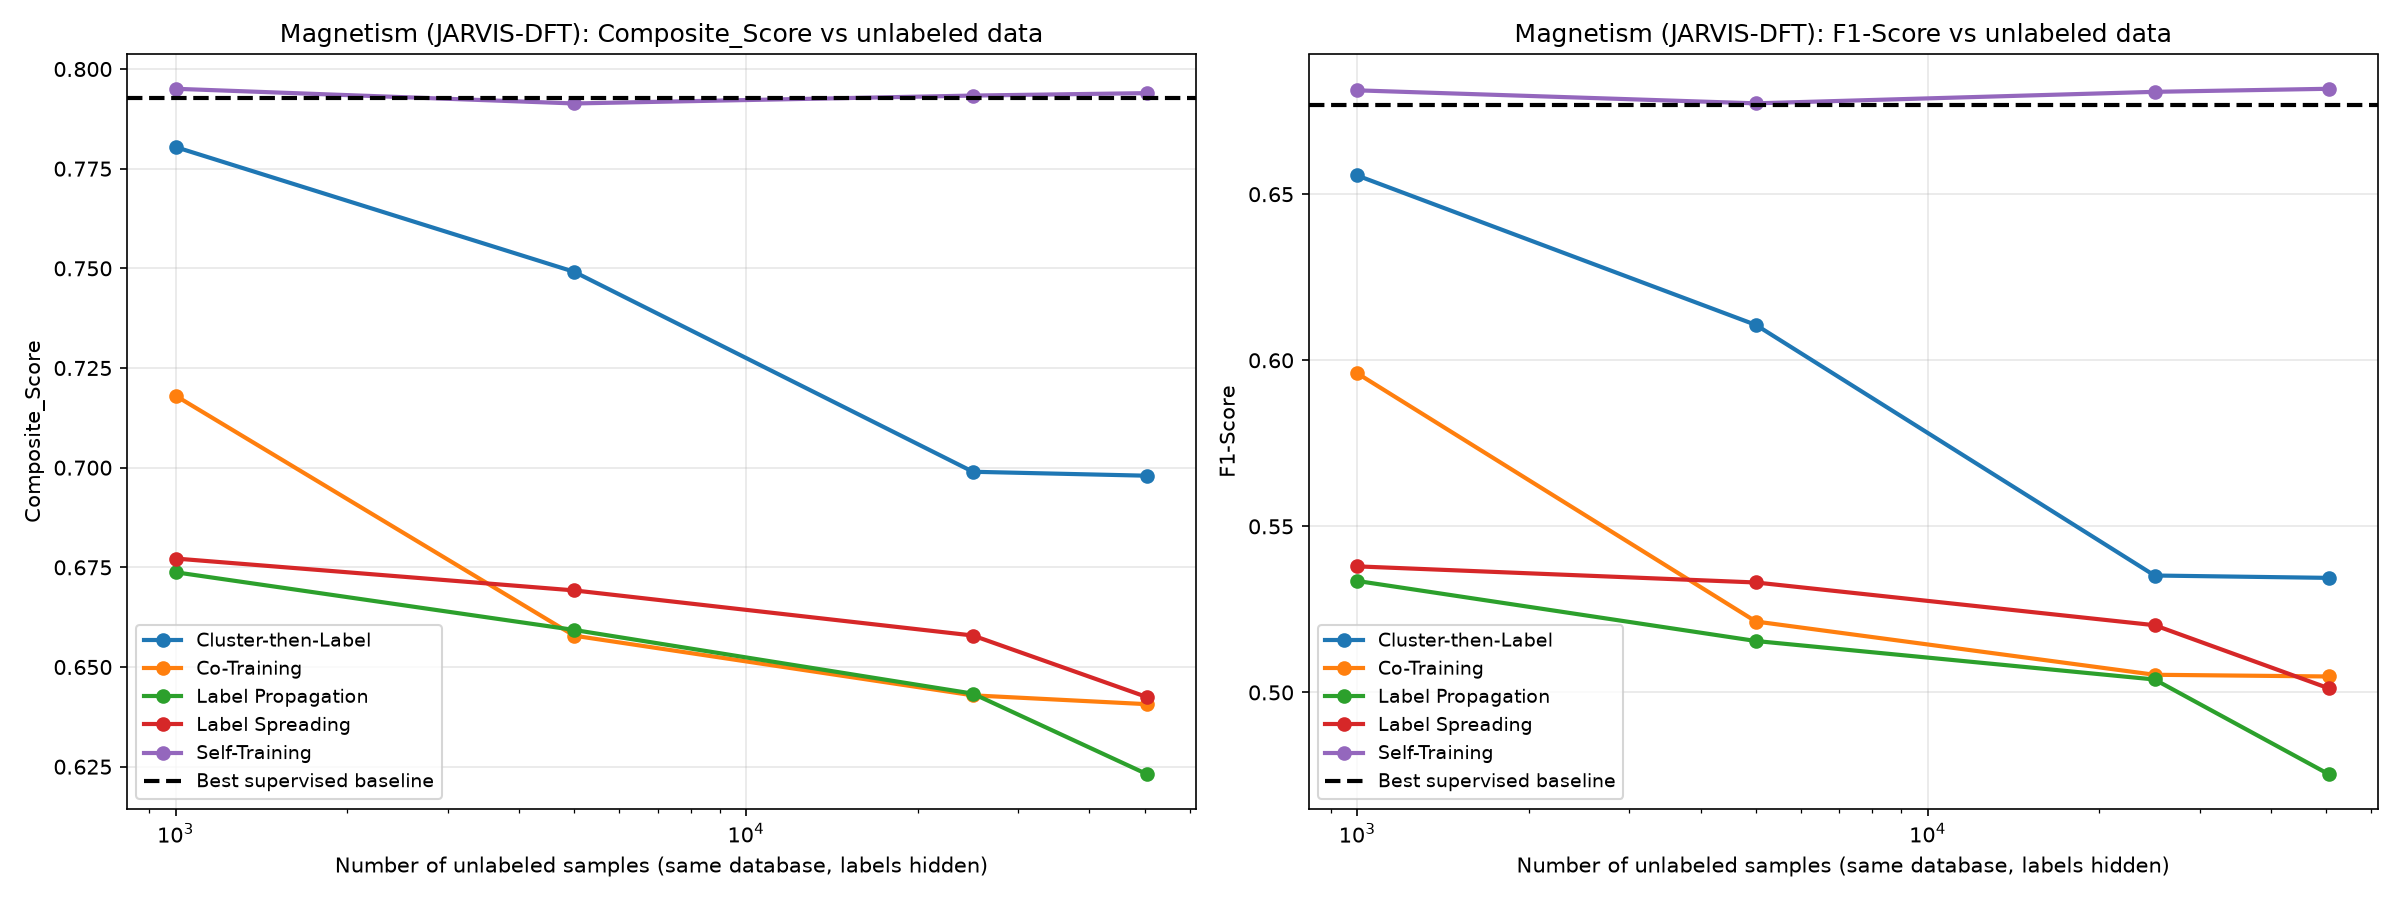

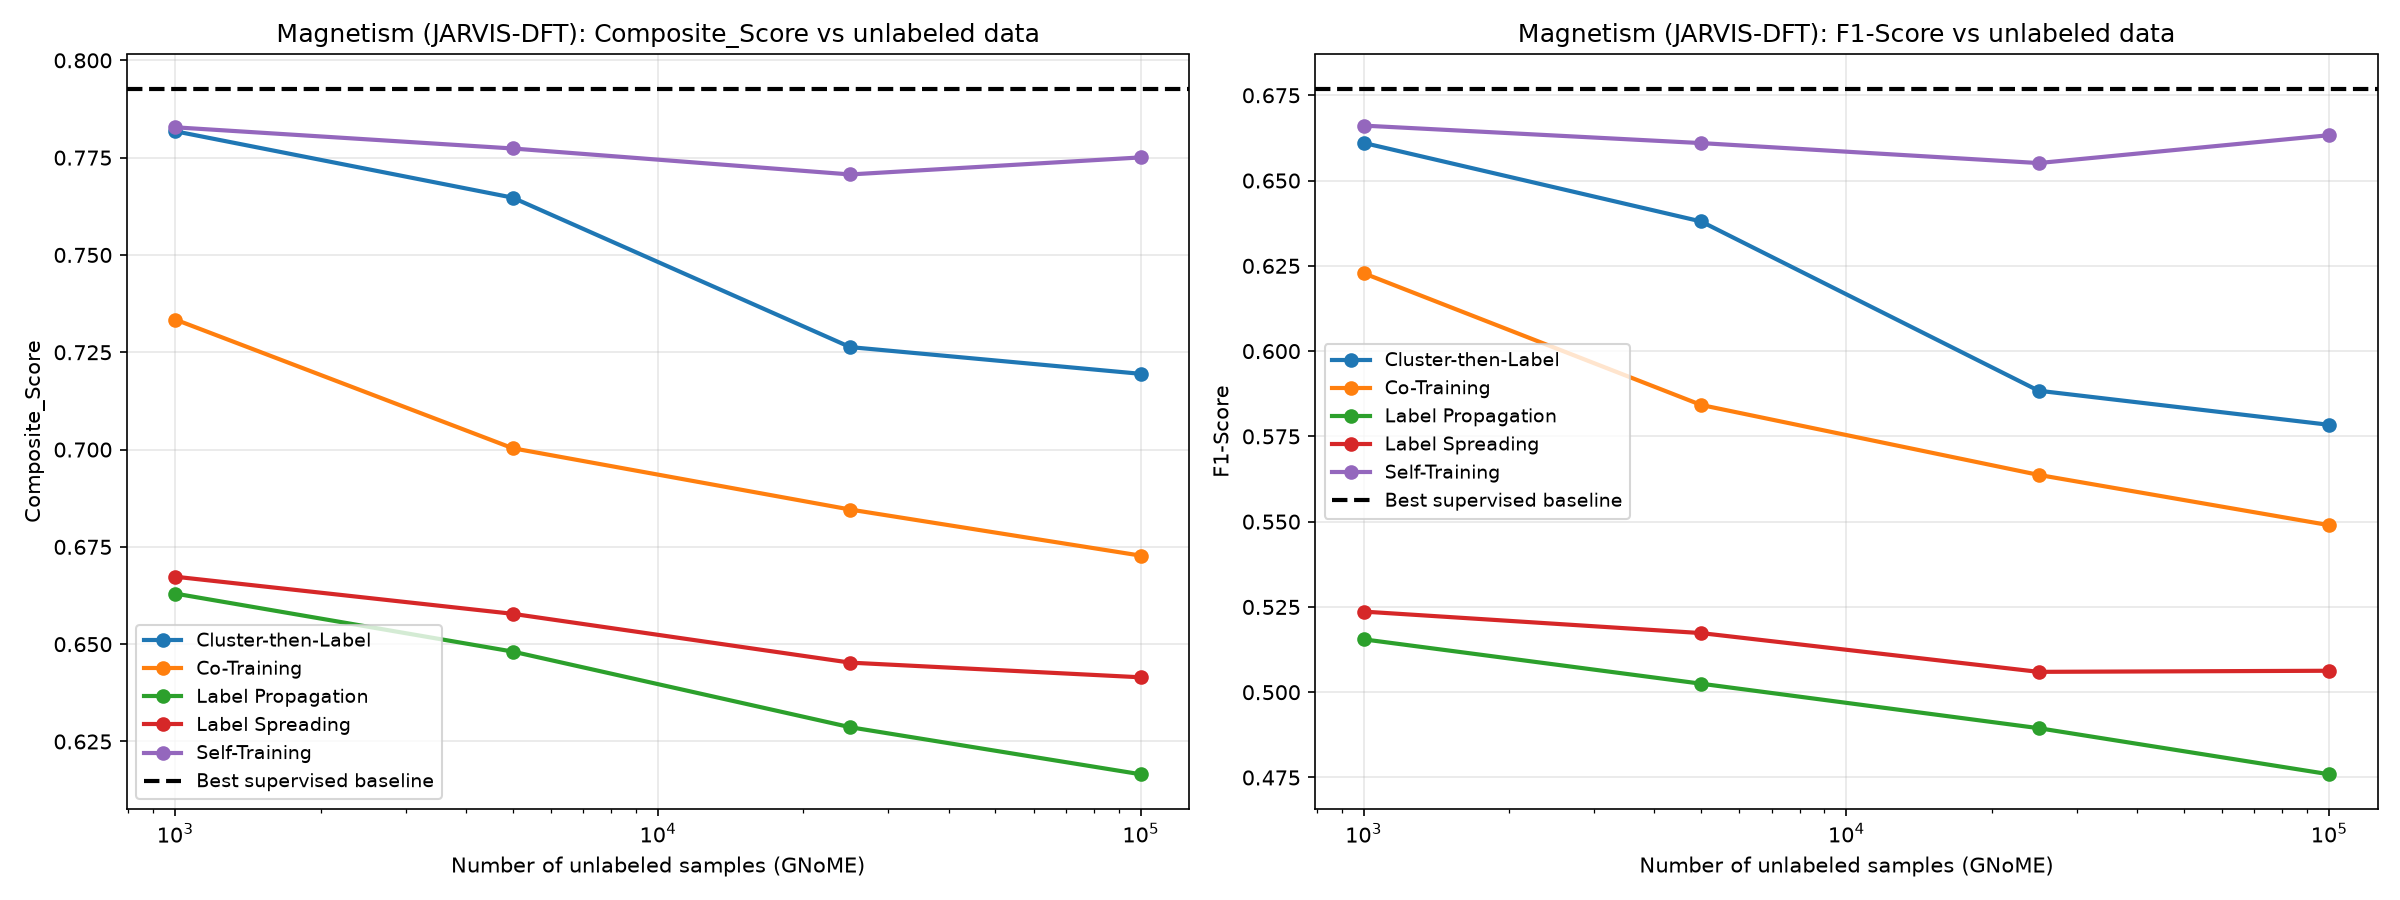

In [8]:
print("STEP 10: LEARNING CURVES")
for p in summ:
    display(Image(str(PRED / p / f'{TASK}_learning_curves.png')))

STEP 11: BEST MODELS COMPARISON (balanced composite metric)


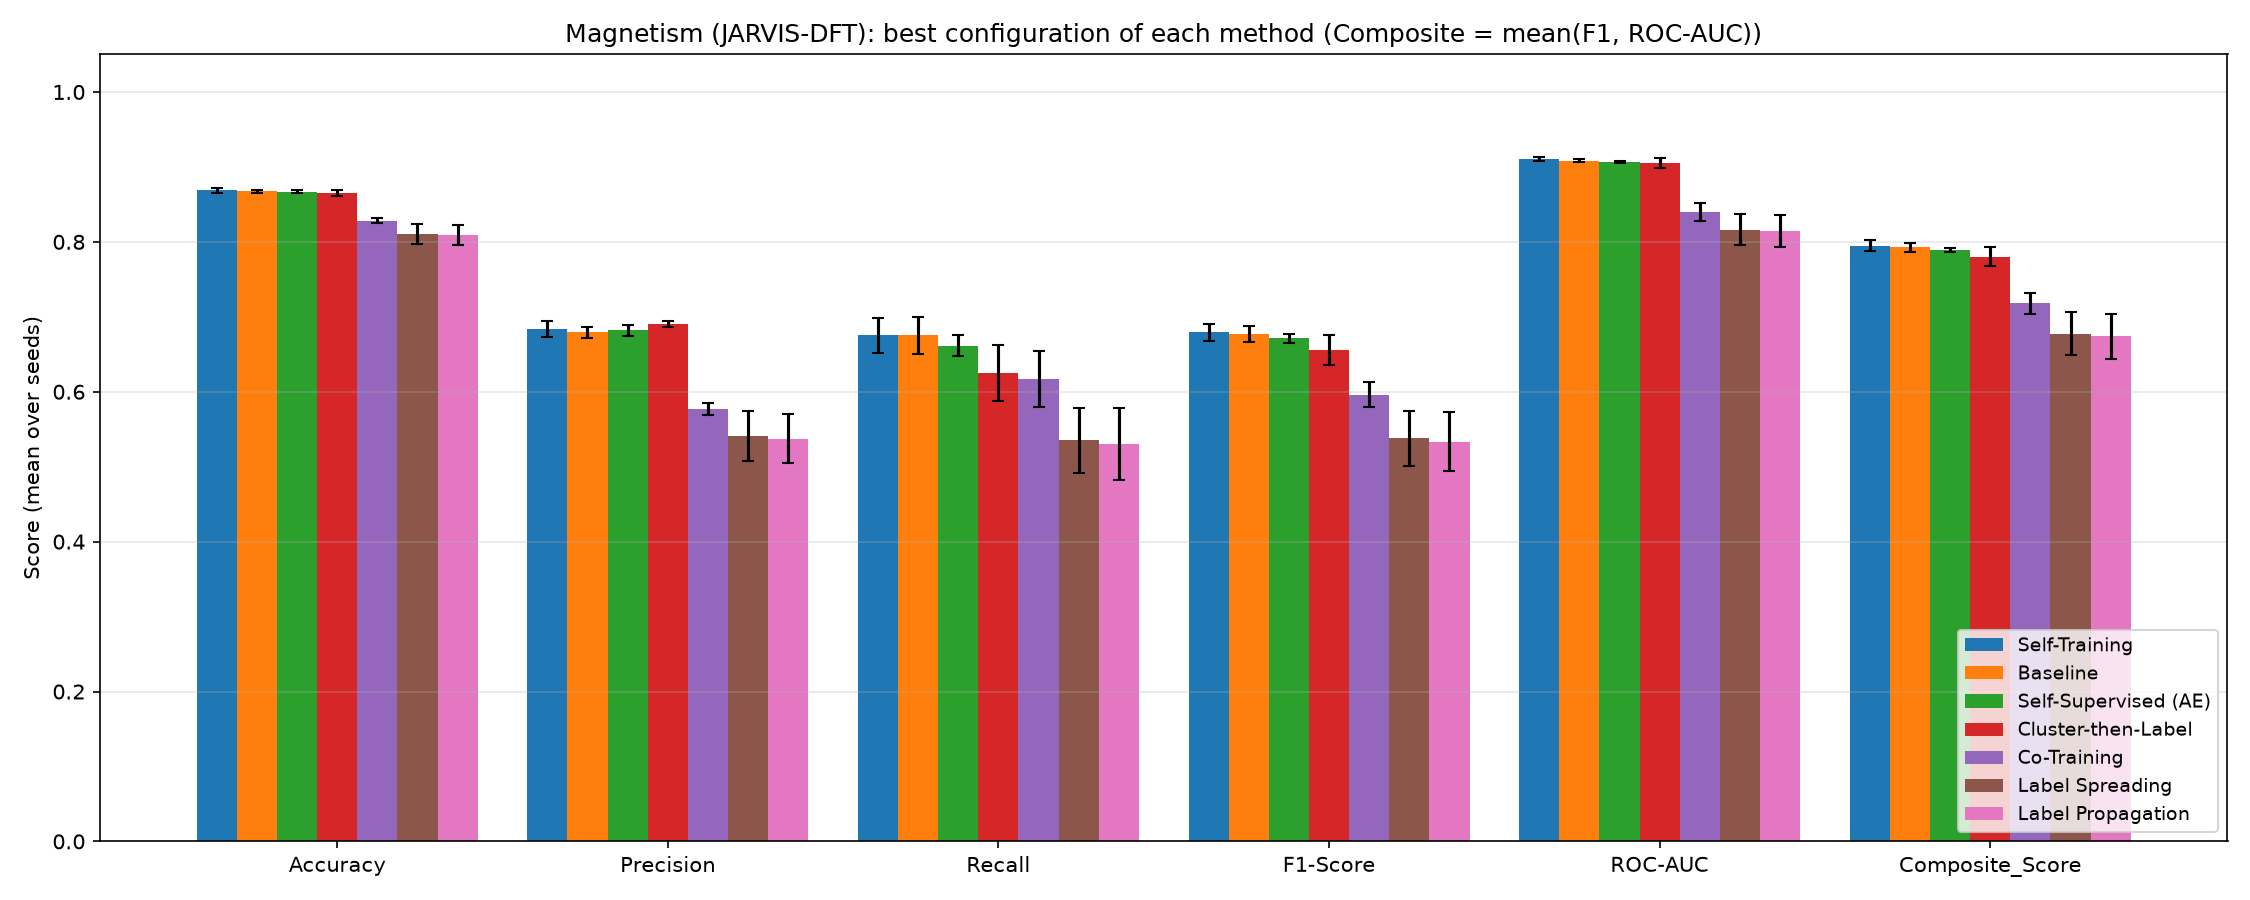

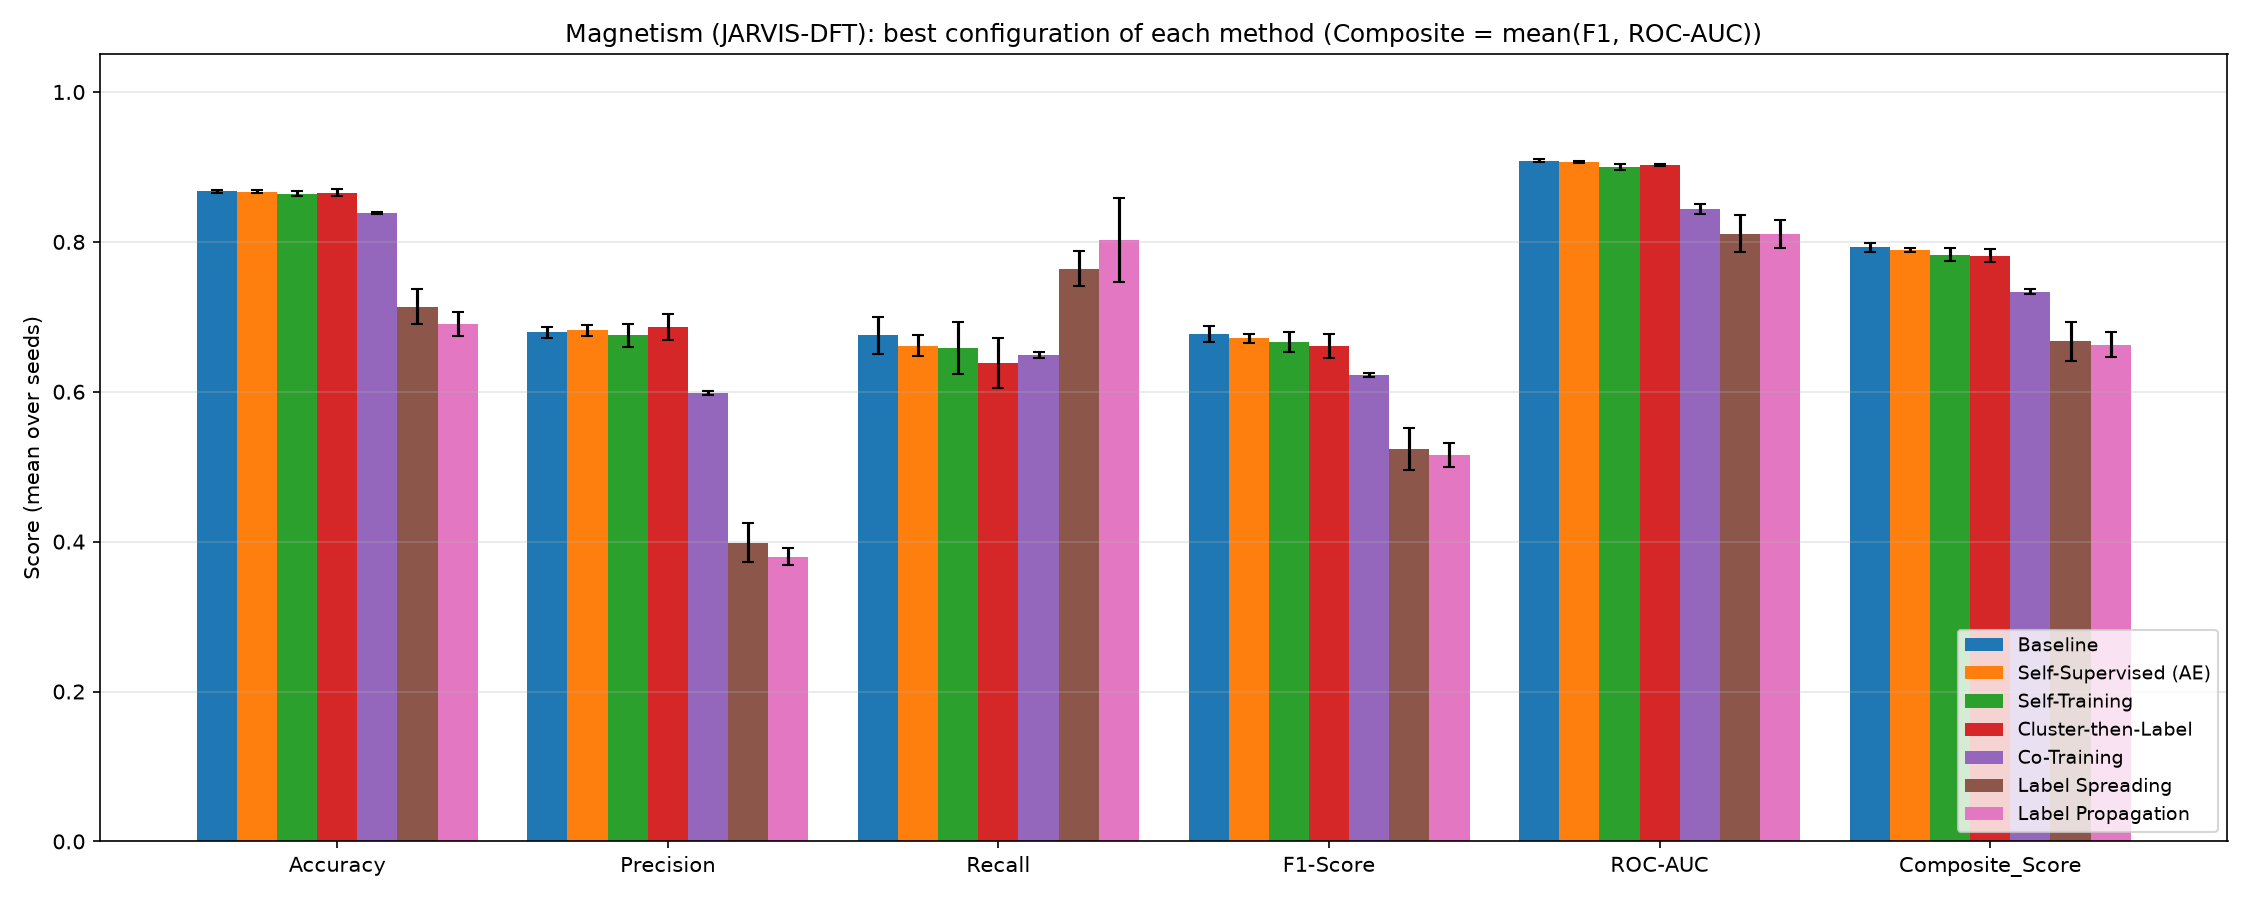

In [9]:
print("STEP 11: BEST MODELS COMPARISON (balanced composite metric)")
for p in summ:
    display(Image(str(PRED / p / f'{TASK}_methods_comparison_balanced.png')))

STEP 12: LABEL-BUDGET CURVE AND FULLY-SUPERVISED UPPER BOUND


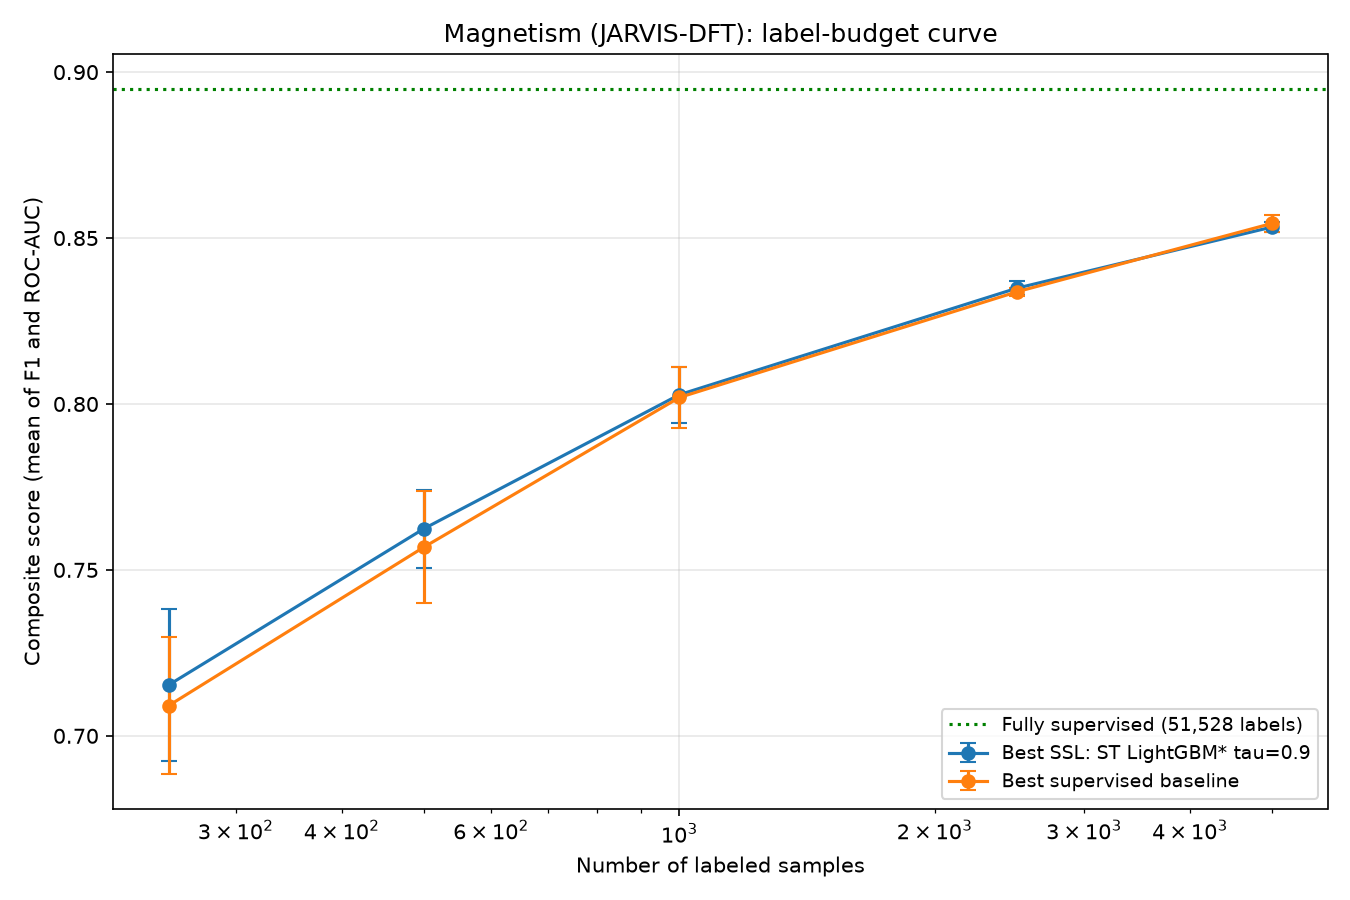

indist fully supervised: {'Composite_Score': 0.8949764176689562, 'F1-Score': 0.8191945158526135, 'ROC-AUC': 0.9707583194852989, 'Accuracy': 0.9181027790715728}


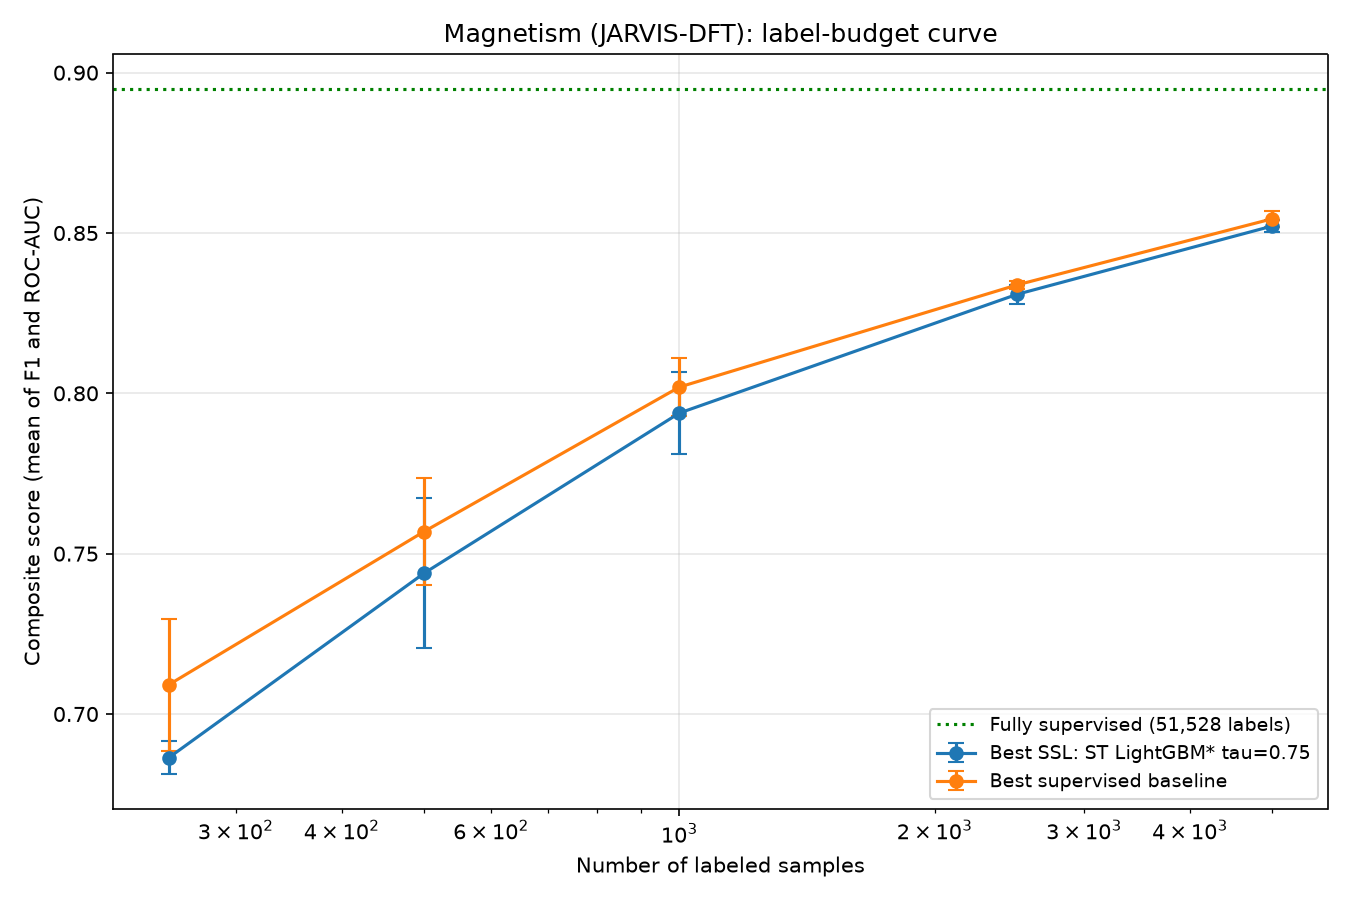

gnome fully supervised: {'Composite_Score': 0.8949764176689562, 'F1-Score': 0.8191945158526135, 'ROC-AUC': 0.9707583194852989, 'Accuracy': 0.9181027790715728}


In [10]:
print("STEP 12: LABEL-BUDGET CURVE AND FULLY-SUPERVISED UPPER BOUND")
for p in summ:
    display(Image(str(PRED / p / f'{TASK}_label_budget_curve.png')))
    print(p, 'fully supervised:', summ[p]['fully_supervised_upper_bound'])

### Live run: every method once (seed 0, 1,000 labels, 5,000 unlabeled)

In [11]:
import ssl_core as core
from run_ssl_experiments import Preprocessor, stratified_take
from featurize import view_columns
from sklearn.model_selection import train_test_split
lab = pd.read_parquet(ROOT / 'data/processed' / f'{TASK}_features.parquet')
feat = [c for c in lab.columns if c.startswith(('MagpieData', 'frac ')) or c.endswith('-norm')]
tr, te = train_test_split(np.arange(len(lab)), test_size=0.2, stratify=lab.target, random_state=42)
prep = Preprocessor().fit(lab.iloc[tr][feat])
Xtr, ytr = prep.transform(lab.iloc[tr][feat]), lab.target.values[tr]
Xte, yte = prep.transform(lab.iloc[te][feat]), lab.target.values[te]
rng = np.random.default_rng(0)
li = stratified_take(ytr, 1000, rng)
rest = rng.permutation(np.setdiff1d(np.arange(len(ytr)), li))[:5000]
keep = stratified_take(yte, min(10000, len(yte)), rng)
d = core.Data(Xtr[li], ytr[li], Xtr[rest], Xte[keep], yte[keep])
v1n, v2n = view_columns()
v2 = [i for i, c in enumerate(prep.cols) if c in v2n or (any(k in c for k in ('Valence', 'Unfilled', 'Column', 'Row')) and (c.endswith(' mean') or c.endswith(' avg_dev')))]
v1 = [i for i in range(len(prep.cols)) if i not in v2]
best = summ['indist']['best_supervised_baseline']['config'].split(' ')[0]
params = summ['indist']['tuned_params'].get(best, {})
runs = [core.run_baseline(d, best, params=params)[0],
        core.run_label_propagation(d, 'knn', n_neighbors=10)[0],
        core.run_label_propagation(d, 'knn', n_neighbors=10, spreading=True)[0],
        core.run_self_training(d, best, threshold=0.9, max_iter=5, params=params)[0],
        core.run_co_training(d, v1, v2, best, threshold=0.85, n_rounds=8, params=params)[0],
        core.run_cluster_then_label(d, best, params=params)[0]]
pd.DataFrame(runs)[['Model', 'Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC', 'Composite_Score', 'Training_Time']].round(4)

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,Composite_Score,Training_Time
0,Baseline LightGBM (1000 labeled),0.8696,0.6755,0.7051,0.6900,0.9007,0.7953,1.1588
1,"LabelPropagation (knn, k=10, n=5000)",0.7956,0.5034,0.5015,0.5024,0.8086,0.6555,1.0066
2,"LabelSpreading (knn, k=10, alpha=0.2, n=5000)",0.8055,0.5274,0.5287,0.5280,0.8128,0.6704,0.7180
3,"SelfTraining-LightGBM (tau=0.9, n=5000)",0.8705,0.6794,0.7021,0.6906,0.9048,0.7977,20.5291
4,"CoTraining-LightGBM (tau=0.85, n=5000)",0.7981,0.5087,0.5530,0.5299,0.8031,0.6665,54.7652
5,"ClusterThenLabel-LightGBM (k=100, purity=0.8, ...",0.8473,0.6568,0.5403,0.5929,0.8815,0.7372,5.3474


In [12]:
print("STEP 13: DEPLOYED MODEL (selected architecture re-trained on all training labels)")
for p, s in summ.items():
    print(p, s['best_ssl_model']['Model_Config'], '->', s['deployment_model_test_metrics'])

STEP 13: DEPLOYED MODEL (selected architecture re-trained on all training labels)
indist ST LightGBM* tau=0.9 | n=1000 -> {'Composite_Score': 0.8946970376531898, 'F1-Score': 0.8185697217955282, 'ROC-AUC': 0.9708243535108514, 'Accuracy': 0.9174817574910729, 'Precision': 0.7475062344139651, 'Recall': 0.9045643153526971}
gnome ST LightGBM* tau=0.75 | n=1000 -> {'Composite_Score': 0.894494101242721, 'F1-Score': 0.8179491554342262, 'ROC-AUC': 0.9710390470512159, 'Accuracy': 0.9171712467008228, 'Precision': 0.7467289719626168, 'Recall': 0.9041870992078461}
